# H3 FIRMS data exploration

This notebook explores the FIRMS observations after assigning each detection to an H3 cell. It uses the 2018–2024 BC May–September dataset and does not create labels or model inputs yet.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'experiments').exists() and (ROOT.parent / 'experiments').exists():
    ROOT = ROOT.parent
DATA = ROOT / 'experiments/firms_summer_2018_2024/data'
INPUT = DATA / 'firms_h3_detections.csv'
assert INPUT.exists(), f'Missing transformed dataset: {INPUT}'
df = pd.read_csv(INPUT, parse_dates=['acq_date'])
df['year'] = df.acq_date.dt.year
df['month'] = df.acq_date.dt.month
print(f'Rows: {len(df):,}')
print(f'Columns: {len(df.columns)}')
print(f'Unique H3 cells: {df.h3_cell.nunique():,}')
display(df.head())

Rows: 884,963
Columns: 18
Unique H3 cells: 22,314


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type,h3_cell,year,month
0,56.74350,-120.63155,303.52,0.39,0.44,2018-05-01,944,SNPP,SNPP,n,2,270.03,1.08,N,0,87121c6b3ffffff,2018,5
1,56.74405,-120.63811,298.80,0.39,0.44,2018-05-01,944,SNPP,SNPP,n,2,270.32,1.08,N,0,87121c694ffffff,2018,5
2,54.55235,-128.60187,299.32,0.40,0.44,2018-05-01,1125,SNPP,SNPP,n,2,272.73,0.48,N,0,87128461effffff,2018,5
3,49.11012,-121.93166,331.96,0.49,0.40,2018-05-01,2113,SNPP,SNPP,n,2,290.68,4.32,D,0,8728d3a9cffffff,2018,5
4,49.25311,-121.80676,325.54,0.49,0.41,2018-05-01,2113,SNPP,SNPP,n,2,290.73,0.91,D,0,8728d33a3ffffff,2018,5


## 1. Observations over time

These plots show satellite detections, not unique wildfires. Large differences between years may reflect fire activity, observation conditions, or source coverage.

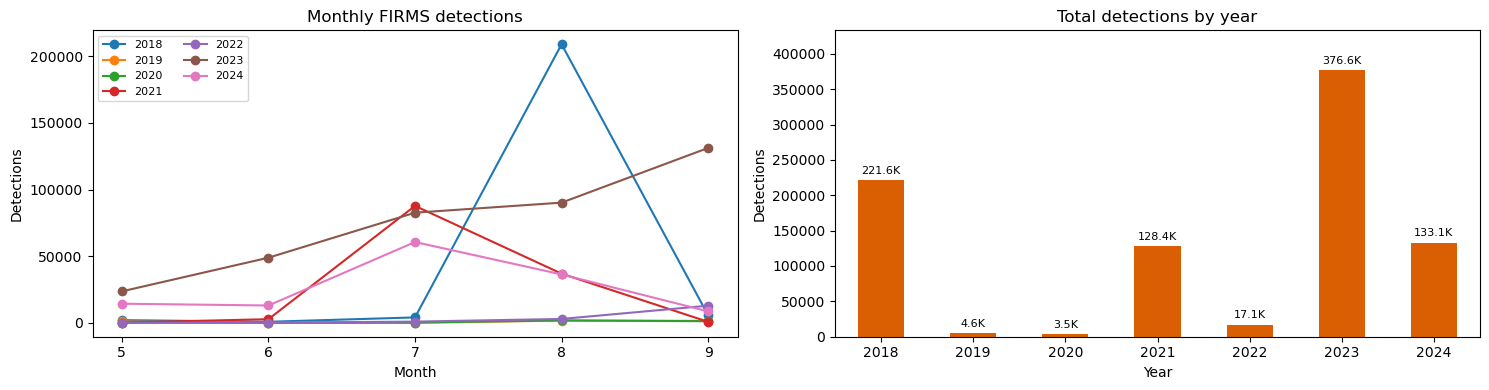

In [2]:
monthly = df.groupby(['year', 'month']).size().rename('detections').reset_index()
yearly = df.groupby('year').size().rename('detections')
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for year, group in monthly.groupby('year'):
    axes[0].plot(group.month, group.detections, marker='o', label=str(year))
yearly.plot.bar(ax=axes[1], color='#d95f02')
axes[0].set(title='Monthly FIRMS detections', xlabel='Month', ylabel='Detections', xticks=[5,6,7,8,9])
axes[0].legend(ncol=2, fontsize=8)
axes[1].set(title='Total detections by year', xlabel='Year', ylabel='Detections')
axes[1].bar_label(axes[1].containers[0], labels=[f'{v/1000:.1f}K' if v >= 1000 else str(int(v)) for v in yearly.values], padding=3, fontsize=8)
axes[1].tick_params(axis='x', rotation=0)
axes[1].margins(y=.15)
plt.tight_layout()
plt.show()

## 2. Spatial activity and cell counts

The transformed rows retain the original coordinates, so we can inspect detection locations while using H3 cells for aggregation.

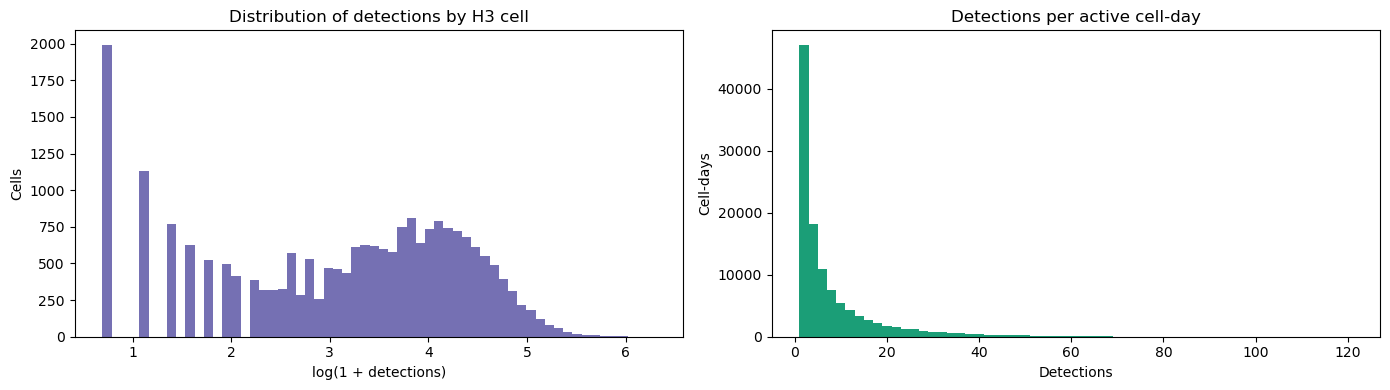

,detections
h3_cell,
8728de989ffffff,545
871206363ffffff,380
871206d5bffffff,375
8712062d5ffffff,348
87120624bffffff,345
871202164ffffff,321
871206248ffffff,315
871202a01ffffff,298
871206502ffffff,298


Cell-days: 114,795
Median detections per active cell: 28


In [3]:
cell_counts = df.groupby('h3_cell').size().sort_values(ascending=False)
cell_days = df.groupby(['h3_cell', 'acq_date']).size()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(np.log1p(cell_counts), bins=60, color='#7570b3')
axes[0].set(title='Distribution of detections by H3 cell', xlabel='log(1 + detections)', ylabel='Cells')
axes[1].hist(cell_days, bins=60, color='#1b9e77')
axes[1].set(title='Detections per active cell-day', xlabel='Detections', ylabel='Cell-days')
plt.tight_layout()
plt.show()
display(cell_counts.head(15).rename('detections').to_frame())
print(f'Cell-days: {len(cell_days):,}')
print(f'Median detections per active cell: {cell_counts.median():.0f}')

## 3. A small temporal sample of cells

These examples show how activity varies across individual H3 cells. They are descriptive samples, not selected training examples.

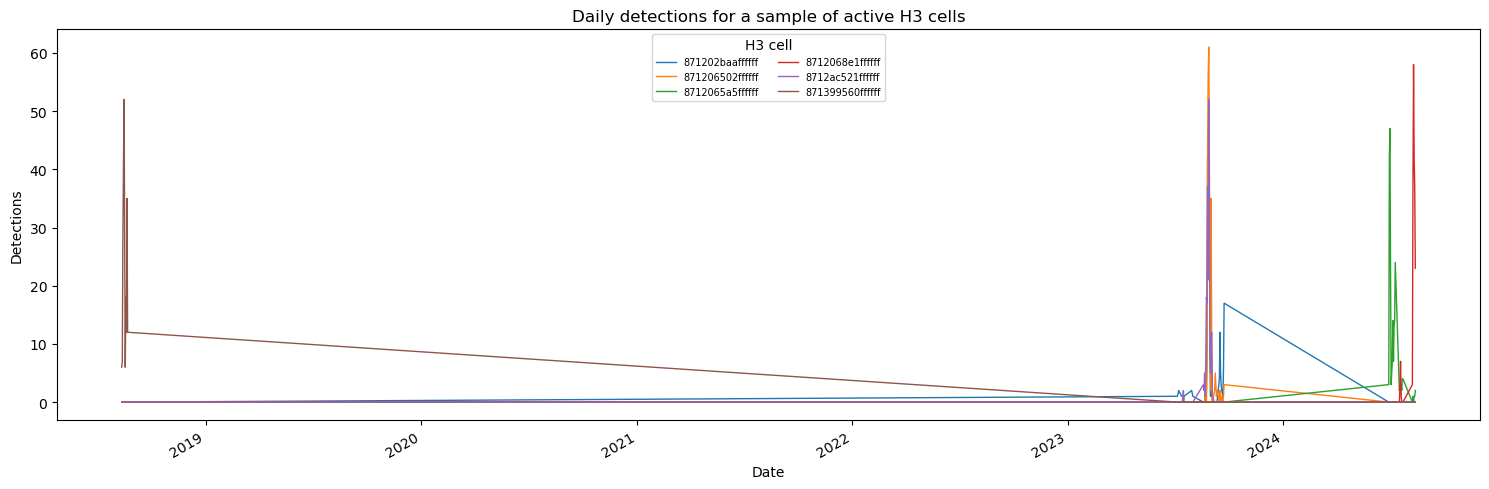

,mean,median,max
h3_cell,,,
871202baaffffff,3.352113,0.0,43.0
871206502ffffff,4.197183,0.0,61.0
8712065a5ffffff,3.126761,0.0,47.0
8712068e1ffffff,2.971831,0.0,58.0
8712ac521ffffff,3.352113,0.0,52.0
871399560ffffff,3.056338,0.0,52.0


In [4]:
rng = np.random.default_rng(42)
sample_cells = rng.choice(cell_counts.head(100).index.to_numpy(), size=min(6, len(cell_counts)), replace=False)
sample_daily = df[df.h3_cell.isin(sample_cells)].groupby(['acq_date', 'h3_cell']).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(15, 5))
sample_daily.plot(ax=ax, linewidth=1)
ax.set(title='Daily detections for a sample of active H3 cells', xlabel='Date', ylabel='Detections')
ax.legend(title='H3 cell', fontsize=7, ncol=2)
plt.tight_layout()
plt.show()
display(sample_daily.describe().T[['mean', '50%', 'max']].rename(columns={'50%':'median'}))

## H3 activity by season

Each panel shows active H3 cells for one year. Cell colour represents the number of FIRMS detections in that year.

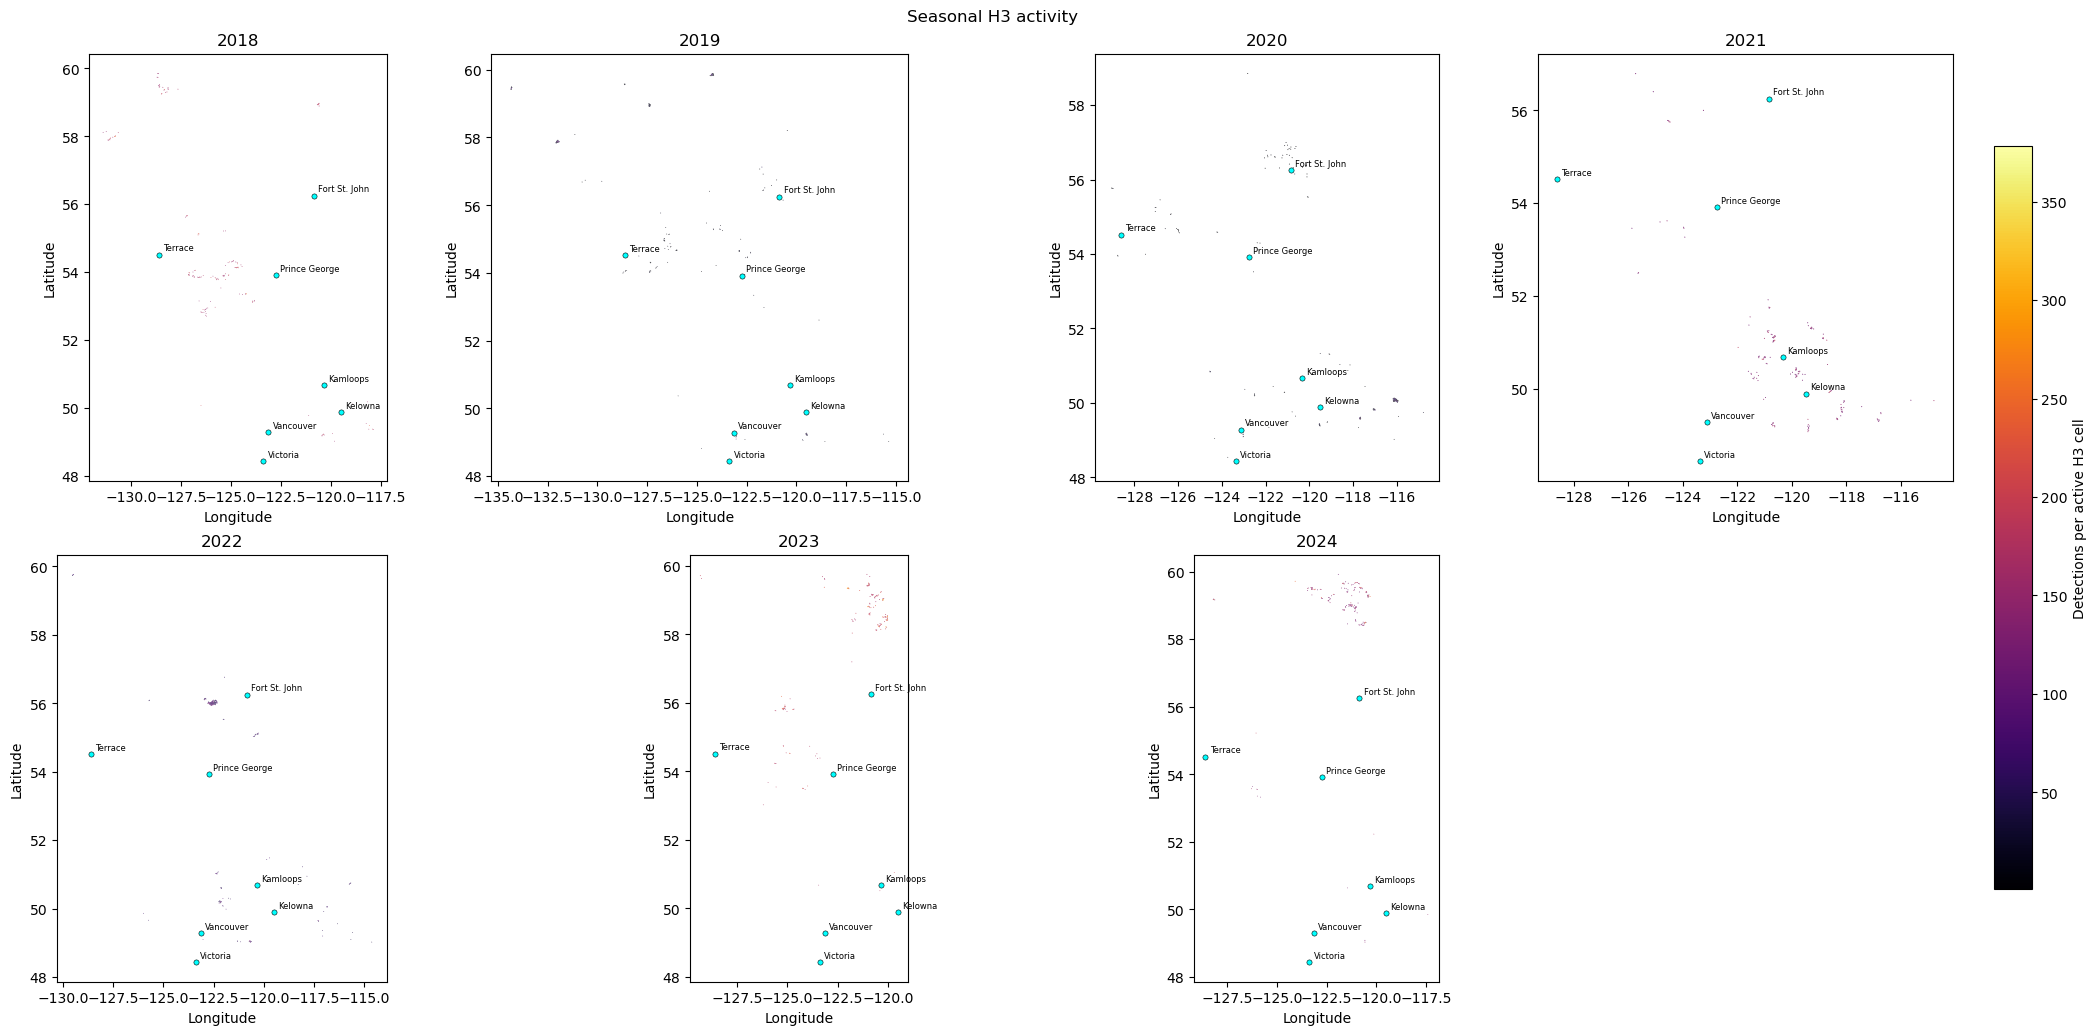

In [5]:
import h3
from matplotlib.collections import PolyCollection

def h3_polygon(cell):
    boundary = h3.cell_to_boundary(cell)
    return [(lon, lat) for lat, lon in boundary] + [(boundary[0][1], boundary[0][0])]

def plot_h3_periods(frame, period_column, periods, top_n=150, title='H3 activity', reference_cities=None):
    counts_by_period = {period: frame.loc[frame[period_column] == period].groupby('h3_cell').size().nlargest(top_n) for period in periods}
    maximum = max((counts.max() for counts in counts_by_period.values() if len(counts)), default=1)
    ncols = min(4, len(periods))
    nrows = int(np.ceil(len(periods) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 5.0 * nrows), squeeze=False, constrained_layout=True)
    axes = axes.ravel()
    cities = reference_cities or {
        'Victoria': (48.4284, -123.3656),
        'Vancouver': (49.2827, -123.1207),
        'Kelowna': (49.8880, -119.4960),
        'Kamloops': (50.6745, -120.3273),
        'Prince George': (53.9171, -122.7497),
        'Terrace': (54.5182, -128.6032),
        'Fort St. John': (56.2524, -120.8460),
    }
    for ax, period in zip(axes, periods):
        counts = counts_by_period[period]
        polygons = [h3_polygon(cell) for cell in counts.index]
        collection = PolyCollection(polygons, array=counts.to_numpy(), cmap='inferno', edgecolors='none')
        collection.set_clim(1, maximum)
        ax.add_collection(collection)
        ax.autoscale()
        ax.set_aspect(1 / np.cos(np.deg2rad(54)))
        city_lats = [lat for lat, lon in cities.values()]
        city_lons = [lon for lat, lon in cities.values()]
        ax.scatter(city_lons, city_lats, s=14, c='cyan', edgecolors='black', linewidths=.4, zorder=4)
        for name, (lat, lon) in cities.items():
            ax.annotate(name, (lon, lat), xytext=(3, 3), textcoords='offset points', fontsize=6, color='black', zorder=5)
        ax.set(title=str(period), xlabel='Longitude', ylabel='Latitude')
    for ax in axes[len(periods):]:
        ax.set_visible(False)
    fig.colorbar(collection, ax=axes[:len(periods)].tolist(), label='Detections per active H3 cell', shrink=.8, pad=0.02)
    fig.suptitle(title, y=1.02)
    plt.show()

plot_h3_periods(df, 'year', sorted(df.year.unique()), top_n=150, title='Seasonal H3 activity')

## H3 activity by week

This view selects the six busiest weeks and maps their active cells. It shows how activity moves across the season without creating hundreds of difficult-to-review panels.

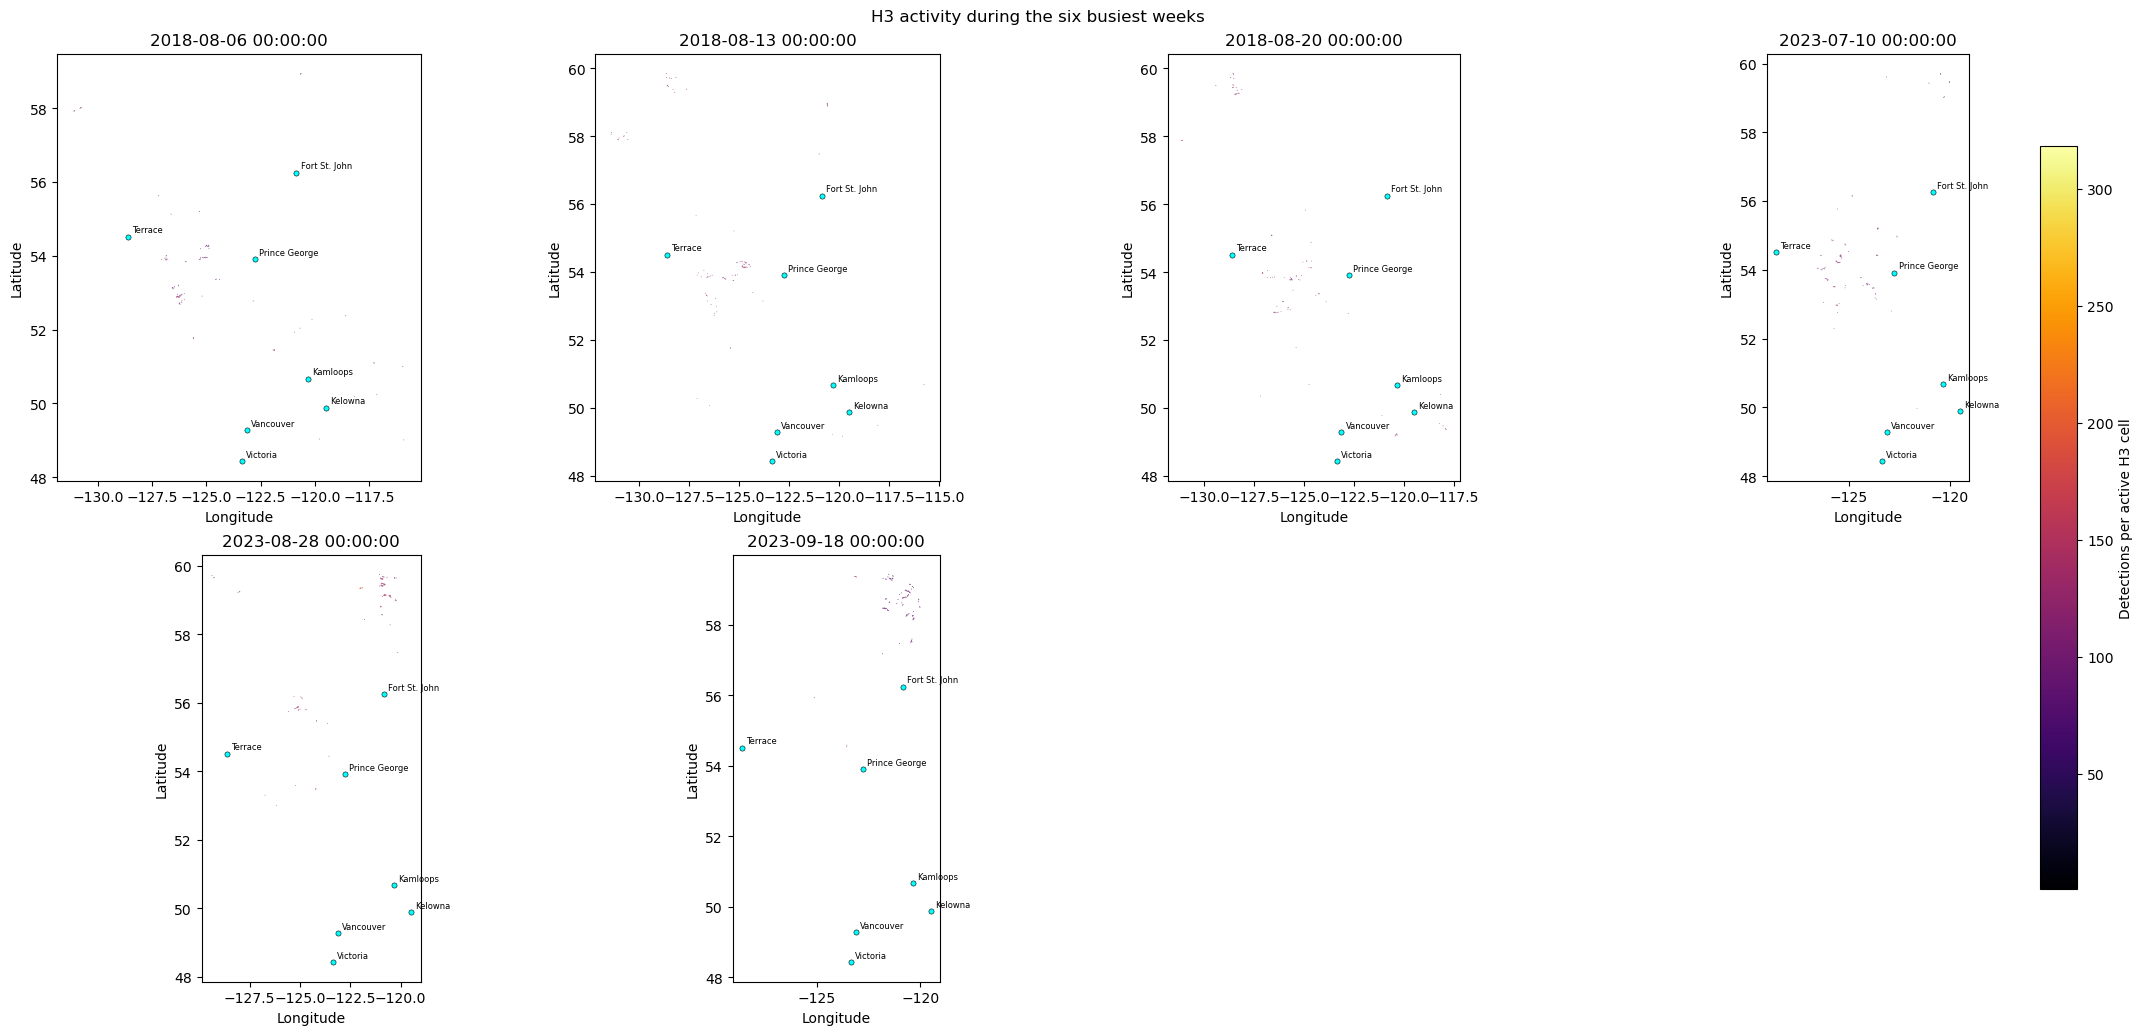

,detections
week_start,
2018-08-13,75505
2018-08-20,74240
2023-08-28,62998
2018-08-06,47792
2023-09-18,47371
2023-07-10,38985
2023-09-11,30674
2024-07-15,28919
2021-07-26,28504


In [6]:
df['week_start'] = df.acq_date.dt.to_period('W-SUN').apply(lambda period: period.start_time)
weekly_counts = df.groupby('week_start').size().sort_values(ascending=False)
busiest_weeks = sorted(weekly_counts.head(6).index)
plot_h3_periods(df, 'week_start', busiest_weeks, top_n=100, title='H3 activity during the six busiest weeks')
display(weekly_counts.head(10).rename('detections').to_frame())

## What this tells us

- H3 gives every detection a stable spatial node identifier.
- Cell-level counts are highly uneven; many cells are quiet while a small number contain many detections.
- Repeated detections and long fire duration can dominate cell counts.
- The next step is to create a complete cell-date table, define observation coverage, and add future activity labels.
- The plots use original coordinates and H3 assignments; the graph should use H3 neighbours rather than plotting bins.

## Monthly H3 activity in Kamloops Fire Centre

June?September 2018 in a 2?2 grid using the cached Fire Centre boundary from notebook 01 (not the municipal boundary). Detections inside the region are aggregated by month and H3 cell; border cells may extend beyond the outline. All panels share geographic limits and a logarithmic colour scale. Blank areas indicate no recorded detections, not confirmed absence of fire.


In [ ]:
%pip install shapely

import calendar
import json
from shapely.geometry import shape
from shapely import intersects_xy, make_valid
import h3
from matplotlib.collections import PolyCollection
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable

selected_city = 'Kamloops'
selected_year = 2018
months = [6, 7, 8, 9]  # June?September; edit to choose four different months.
city_lat, city_lon = 50.6745, -120.3273

# Use the same cached Fire Centre boundary as notebook 01.
boundary_path = ROOT / 'data/region_exploration/fire_centres.geojson'
regions_json = json.loads(boundary_path.read_text(encoding='utf-8'))
region_feature = next(
    feature for feature in regions_json['features']
    if feature['properties']['MOF_FIRE_CENTRE_NAME'] == 'Kamloops Fire Centre'
)
geometry = make_valid(shape(region_feature['geometry']))

def boundary_polygons(geom):
    if geom.geom_type == 'Polygon':
        yield geom
    else:
        for part in getattr(geom, 'geoms', []):
            yield from boundary_polygons(part)

min_lon, min_lat, max_lon, max_lat = geometry.bounds
lon_limits = (min_lon - .08, max_lon + .08)
lat_limits = (min_lat - .08, max_lat + .08)
window = df.loc[
    (df['year'] == selected_year) & df['month'].isin(months)
].copy()
window = window.loc[intersects_xy(
    geometry, window['longitude'].to_numpy(), window['latitude'].to_numpy()
)].copy()
monthly_counts = {
    month: window.loc[window['month'] == month].groupby('h3_cell').size()
    for month in months
}
maximum = max((int(counts.max()) for counts in monthly_counts.values() if not counts.empty), default=1)
norm = LogNorm(vmin=1, vmax=max(2, maximum))

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True,
                         constrained_layout=True)
for ax, month in zip(axes.flat, months):
    for polygon in boundary_polygons(geometry):
        ax.plot(*polygon.exterior.xy, color='gray', linewidth=.8, zorder=2)
        for ring in polygon.interiors:
            ax.plot(*ring.xy, color='gray', linewidth=.6, zorder=2)
    counts = monthly_counts[month]
    polygons = [
        [(lon, lat) for lat, lon in h3.cell_to_boundary(cell)]
        for cell in counts.index
    ]
    if polygons:
        collection = PolyCollection(
            polygons, array=counts.to_numpy(dtype=float), cmap='Oranges',
            norm=norm, edgecolors='none',
        )
        ax.add_collection(collection)
    else:
        ax.text(.5, .5, 'No recorded detections', transform=ax.transAxes,
                ha='center', va='center')
    ax.set(title=f'{calendar.month_name[month]} {selected_year} ({counts.sum():,} detections)',
           xlabel='Longitude', ylabel='Latitude', xlim=lon_limits, ylim=lat_limits)
    ax.set_aspect(1 / np.cos(np.deg2rad(city_lat)))
    ax.set_axisbelow(True)
    ax.grid(True, linestyle=':', linewidth=.6, color='gray', alpha=.4)

fig.colorbar(ScalarMappable(norm=norm, cmap='Oranges'), ax=axes.ravel().tolist(),
             label='FIRMS detections per H3 cell per month (log scale)', shrink=.85)
fig.suptitle(f'Monthly hotspot activity in {selected_city} Fire Centre, {selected_year}\n'
             'Shared colour scale across months', fontsize=14)
plt.show()


## Weekly H3 activity in Kamloops: August 2018

Four periods cover August 1-7, 8-14, 15-21, and 22-31. The final period has ten days, so raw counts are not equal-duration comparisons. Uses the existing H3 resolution and Kamloops Fire Centre boundary from the monthly cell above.


In [ ]:
# Run the monthly Kamloops plotting cell above first for the region boundary.
weekly_window = df.loc[
    (df['year'] == 2018) & (df['month'] == 8)
].copy()
weekly_window = weekly_window.loc[intersects_xy(
    geometry, weekly_window['longitude'].to_numpy(), weekly_window['latitude'].to_numpy()
)].copy()

# Four panels covering all of August; the final period contains ten days.
week_ranges = [(1, 7), (8, 14), (15, 21), (22, 31)]
weekly_h3_counts = {
    (start, end): weekly_window.loc[
        weekly_window['acq_date'].dt.day.between(start, end)
    ].groupby('h3_cell').size()
    for start, end in week_ranges
}
weekly_maximum = max(
    (int(counts.max()) for counts in weekly_h3_counts.values() if not counts.empty),
    default=1,
)
weekly_norm = LogNorm(vmin=1, vmax=max(2, weekly_maximum))
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True,
                         constrained_layout=True)
for ax, (start, end) in zip(axes.flat, week_ranges):
    for polygon in boundary_polygons(geometry):
        ax.plot(*polygon.exterior.xy, color='gray', linewidth=.8, zorder=2)
        for ring in polygon.interiors:
            ax.plot(*ring.xy, color='gray', linewidth=.6, zorder=2)
    counts = weekly_h3_counts[(start, end)]
    if not counts.empty:
        polygons = [
            [(lon, lat) for lat, lon in h3.cell_to_boundary(cell)]
            for cell in counts.index
        ]
        ax.add_collection(PolyCollection(
            polygons, array=counts.to_numpy(dtype=float), cmap='Oranges',
            norm=weekly_norm, edgecolors='none',
        ))
    else:
        ax.text(.5, .5, 'No recorded detections', transform=ax.transAxes,
                ha='center', va='center')
    ax.set(title=f'August {start}-{end}, 2018 ({counts.sum():,} detections)',
           xlabel='Longitude', ylabel='Latitude', xlim=lon_limits, ylim=lat_limits)
    ax.set_aspect(1 / np.cos(np.deg2rad(city_lat)))
    ax.set_axisbelow(True)
    ax.grid(True, linestyle=':', linewidth=.6, color='gray', alpha=.4)
fig.colorbar(ScalarMappable(norm=weekly_norm, cmap='Oranges'),
             ax=axes.ravel().tolist(), shrink=.85,
             label='FIRMS detections per H3 cell per period (log scale)')
fig.suptitle('Kamloops Fire Centre: August 2018 by week\n'
             'Shared colour scale; final period is August 22-31 (10 days)', fontsize=14)
plt.show()


## Summary: observed hotspot activity in Kamloops, 2018

- **August had the most recorded hotspot observations:** 9,648, or about 78% of the June-September total (12,420).
- **Observed activity peaked during August 15-21:** 3,460 detections, averaging 494 per day. This does not establish when the fires ignited.
- **Recorded activity declined in late August:** August 22-31 averaged 242 detections per day. Use daily averages because this panel covers ten days rather than seven.
- **Detections were concentrated in clusters, especially in the south.** Southern clusters recur across August; this alone does not prove persistence or spread of the same fire.
- **September had fewer observations:** 985 detections, about 90% below August.
- **Counts are hotspot observations, not unique fires or new ignitions.** One ongoing fire can produce repeated detections across cells and dates; counts do not directly measure severity or burned area.
- **Blank cells mean no recorded detections**, not confirmed absence of fire; observation coverage still needs checking.
- **Model interpretation:** predict whether a hotspot will be detected in a cell during a future window, including ongoing burning, rather than whether a new fire will start.


## Monthly observed hotspot activity: Kamloops, 2023

June-September 2023 using the same region and H3 aggregation as the 2018 monthly plot. Colours share a scale within this figure; the scale is calculated separately from 2018. Counts represent recorded hotspot observations, not new ignitions.


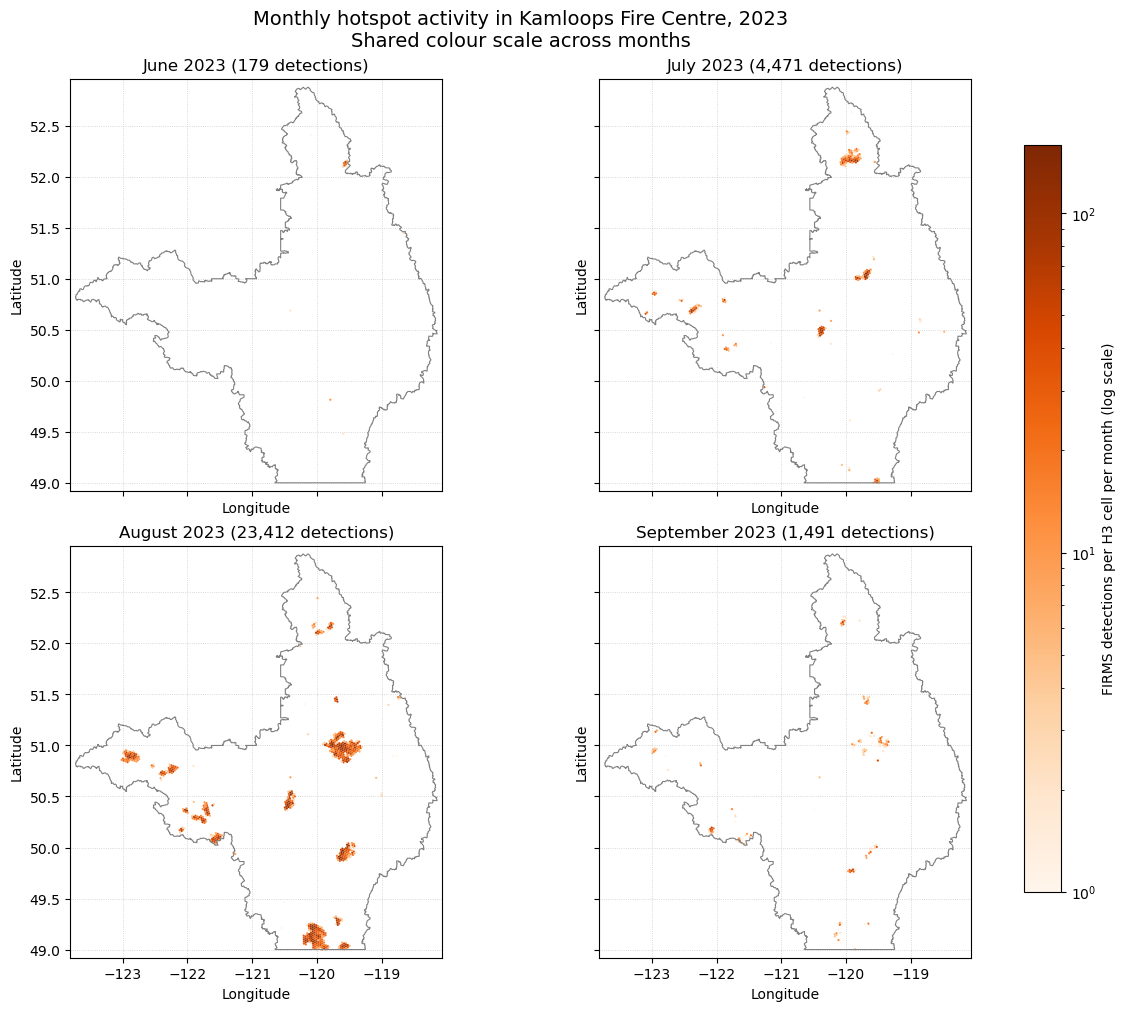

In [20]:

import calendar
import json
from shapely.geometry import shape
from shapely import intersects_xy, make_valid
import h3
from matplotlib.collections import PolyCollection
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable

selected_city = 'Kamloops'
selected_year = 2023
months = [6, 7, 8, 9]  # June?September; edit to choose four different months.
city_lat, city_lon = 50.6745, -120.3273

# Use the same cached Fire Centre boundary as notebook 01.
boundary_path = ROOT / 'data/region_exploration/fire_centres.geojson'
regions_json = json.loads(boundary_path.read_text(encoding='utf-8'))
region_feature = next(
    feature for feature in regions_json['features']
    if feature['properties']['MOF_FIRE_CENTRE_NAME'] == 'Kamloops Fire Centre'
)
geometry = make_valid(shape(region_feature['geometry']))

def boundary_polygons(geom):
    if geom.geom_type == 'Polygon':
        yield geom
    else:
        for part in getattr(geom, 'geoms', []):
            yield from boundary_polygons(part)

min_lon, min_lat, max_lon, max_lat = geometry.bounds
lon_limits = (min_lon - .08, max_lon + .08)
lat_limits = (min_lat - .08, max_lat + .08)
window = df.loc[
    (df['year'] == selected_year) & df['month'].isin(months)
].copy()
window = window.loc[intersects_xy(
    geometry, window['longitude'].to_numpy(), window['latitude'].to_numpy()
)].copy()
monthly_counts = {
    month: window.loc[window['month'] == month].groupby('h3_cell').size()
    for month in months
}
maximum = max((int(counts.max()) for counts in monthly_counts.values() if not counts.empty), default=1)
norm = LogNorm(vmin=1, vmax=max(2, maximum))

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True,
                         constrained_layout=True)
for ax, month in zip(axes.flat, months):
    for polygon in boundary_polygons(geometry):
        ax.plot(*polygon.exterior.xy, color='gray', linewidth=.8, zorder=2)
        for ring in polygon.interiors:
            ax.plot(*ring.xy, color='gray', linewidth=.6, zorder=2)
    counts = monthly_counts[month]
    polygons = [
        [(lon, lat) for lat, lon in h3.cell_to_boundary(cell)]
        for cell in counts.index
    ]
    if polygons:
        collection = PolyCollection(
            polygons, array=counts.to_numpy(dtype=float), cmap='Oranges',
            norm=norm, edgecolors='none',
        )
        ax.add_collection(collection)
    else:
        ax.text(.5, .5, 'No recorded detections', transform=ax.transAxes,
                ha='center', va='center')
    ax.set(title=f'{calendar.month_name[month]} {selected_year} ({counts.sum():,} detections)',
           xlabel='Longitude', ylabel='Latitude', xlim=lon_limits, ylim=lat_limits)
    ax.set_aspect(1 / np.cos(np.deg2rad(city_lat)))
    ax.set_axisbelow(True)
    ax.grid(True, linestyle=':', linewidth=.6, color='gray', alpha=.4)

fig.colorbar(ScalarMappable(norm=norm, cmap='Oranges'), ax=axes.ravel().tolist(),
             label='FIRMS detections per H3 cell per month (log scale)', shrink=.85)
fig.suptitle(f'Monthly hotspot activity in {selected_city} Fire Centre, {selected_year}\n'
             'Shared colour scale across months', fontsize=14)
plt.show()


## Weekly observed hotspot activity: Kamloops, August 2023

Four panels cover August 1-7, 8-14, 15-21, and 22-31. The final period has ten days; raw counts are not equal-duration comparisons. Colours share a scale within this figure. Counts represent recorded hotspot observations, not new ignitions.


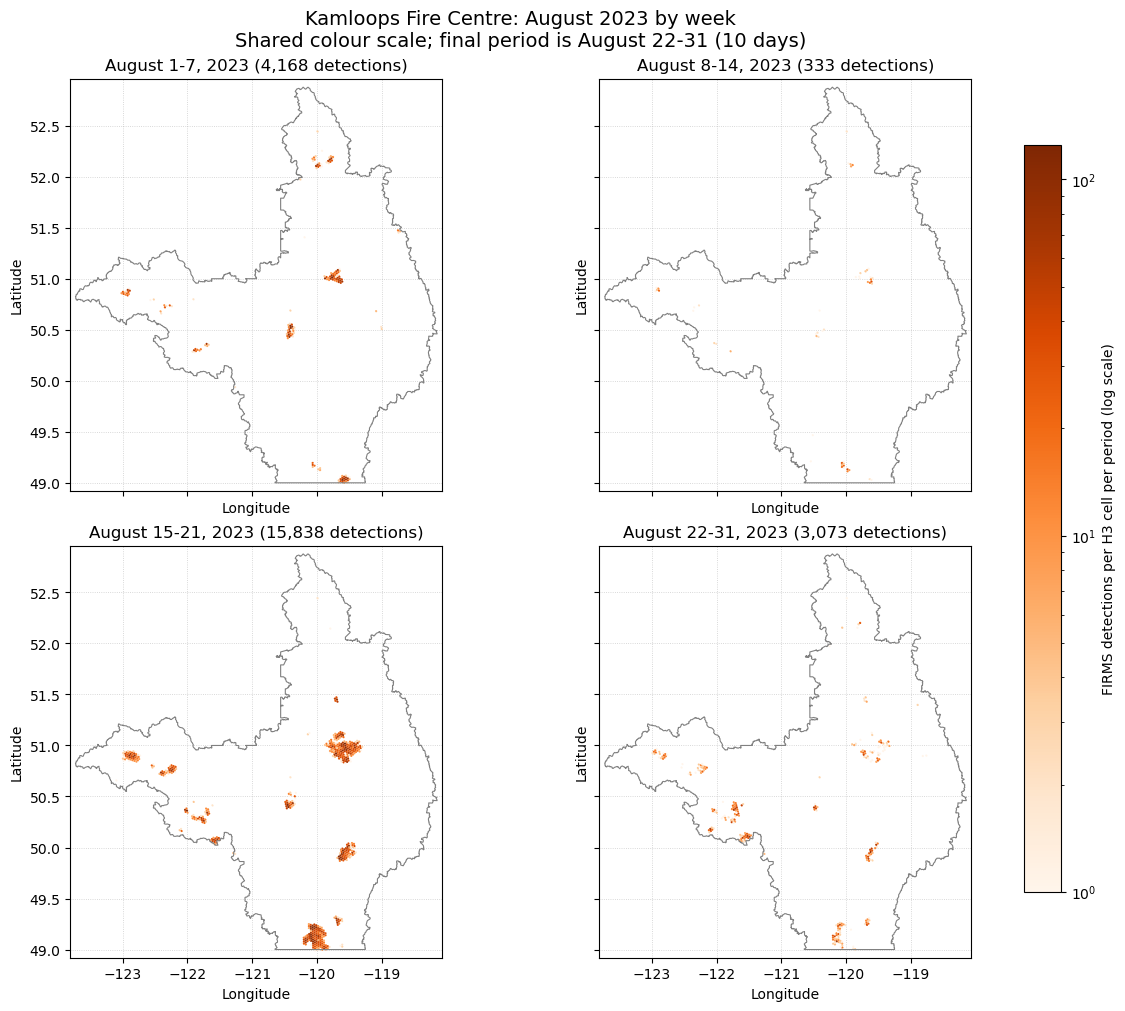

In [21]:
# Run the monthly Kamloops 2023 plotting cell above first for the region boundary.
weekly_window = df.loc[
    (df['year'] == 2023) & (df['month'] == 8)
].copy()
weekly_window = weekly_window.loc[intersects_xy(
    geometry, weekly_window['longitude'].to_numpy(), weekly_window['latitude'].to_numpy()
)].copy()

# Four panels covering all of August; the final period contains ten days.
week_ranges = [(1, 7), (8, 14), (15, 21), (22, 31)]
weekly_h3_counts = {
    (start, end): weekly_window.loc[
        weekly_window['acq_date'].dt.day.between(start, end)
    ].groupby('h3_cell').size()
    for start, end in week_ranges
}
weekly_maximum = max(
    (int(counts.max()) for counts in weekly_h3_counts.values() if not counts.empty),
    default=1,
)
weekly_norm = LogNorm(vmin=1, vmax=max(2, weekly_maximum))
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True,
                         constrained_layout=True)
for ax, (start, end) in zip(axes.flat, week_ranges):
    for polygon in boundary_polygons(geometry):
        ax.plot(*polygon.exterior.xy, color='gray', linewidth=.8, zorder=2)
        for ring in polygon.interiors:
            ax.plot(*ring.xy, color='gray', linewidth=.6, zorder=2)
    counts = weekly_h3_counts[(start, end)]
    if not counts.empty:
        polygons = [
            [(lon, lat) for lat, lon in h3.cell_to_boundary(cell)]
            for cell in counts.index
        ]
        ax.add_collection(PolyCollection(
            polygons, array=counts.to_numpy(dtype=float), cmap='Oranges',
            norm=weekly_norm, edgecolors='none',
        ))
    else:
        ax.text(.5, .5, 'No recorded detections', transform=ax.transAxes,
                ha='center', va='center')
    ax.set(title=f'August {start}-{end}, 2023 ({counts.sum():,} detections)',
           xlabel='Longitude', ylabel='Latitude', xlim=lon_limits, ylim=lat_limits)
    ax.set_aspect(1 / np.cos(np.deg2rad(city_lat)))
    ax.set_axisbelow(True)
    ax.grid(True, linestyle=':', linewidth=.6, color='gray', alpha=.4)
fig.colorbar(ScalarMappable(norm=weekly_norm, cmap='Oranges'),
             ax=axes.ravel().tolist(), shrink=.85,
             label='FIRMS detections per H3 cell per period (log scale)')
fig.suptitle('Kamloops Fire Centre: August 2023 by week\n'
             'Shared colour scale; final period is August 22-31 (10 days)', fontsize=14)
plt.show()
